In [ ]:
import pandas as pd 
import sqlite3
  
con = sqlite3.connect(r'C:\Users\alsab\ipl-cricket-analytics\data\raw\ipl.db') 
  
def q(sql): 
    """Run a SELECT and show the result as a table.""" 
    return pd.read_sql(sql, con)


def run_sql_file(path): 
    """Read a .sql file and execute every statement in it.""" 
    with open(path, 'r') as f: 
        script = f.read() 
    con.executescript(script) 
    con.commit() 
    print('ran', path)

In [ ]:
run_sql_file(r'C:\Users\alsab\ipl-cricket-analytics\sql\practice\09_analysis_views.sql')

ran C:\Users\alsab\ipl-cricket-analytics\sql\practice\09_analysis_views.sql


In [ ]:
#1
q("SELECT * FROM v_ball LIMIT 10;")

,season_id,match_id,batter,bowler,non_striker,over_number,ball_number,batter_runs,extras,total_runs,...,is_super_over,innings,batting_team_id,bowling_team_id,batting_team,bowling_team,phase,is_legal,bowler_runs,bowler_wicket
0,2008,335982,SC Ganguly,P Kumar,BB McCullum,0,0,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
1,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,1,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
2,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,2,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,0,1,0
3,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,3,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
4,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,4,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
5,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,5,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
6,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,6,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
7,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,0,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
8,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,1,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0
9,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,2,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0


In [ ]:
#2
q("SELECT * FROM v_innings LIMIT 10;")

,match_id,innings,batting_team,bowling_team,runs,wickets,legal_balls
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,222,3,120
1,335982,2,Royal Challengers Bangalore,Kolkata Knight Riders,82,10,91
2,335983,1,Chennai Super Kings,Punjab Kings,240,5,120
3,335983,2,Punjab Kings,Chennai Super Kings,207,4,120
4,335984,1,Rajasthan Royals,Delhi Capitals,129,8,120
5,335984,2,Delhi Capitals,Rajasthan Royals,132,1,91
6,335985,1,Mumbai Indians,Royal Challengers Bangalore,165,7,120
7,335985,2,Royal Challengers Bangalore,Mumbai Indians,166,5,118
8,335986,1,Sunrisers Hyderabad,Kolkata Knight Riders,110,10,112
9,335986,2,Kolkata Knight Riders,Sunrisers Hyderabad,112,5,114


In [ ]:
#3
q("""
SELECT match_id,
       innings,
       batting_team,
       runs
FROM v_innings
ORDER BY runs DESC
LIMIT 10;
""")

,match_id,innings,batting_team,runs
0,1426268,1,Sunrisers Hyderabad,287
1,1473439,1,Sunrisers Hyderabad,286
2,1473505,1,Sunrisers Hyderabad,278
3,1422126,1,Sunrisers Hyderabad,277
4,1422134,1,Kolkata Knight Riders,272
5,1426273,1,Sunrisers Hyderabad,266
6,1529278,2,Punjab Kings,265
7,1529278,1,Delhi Capitals,264
8,598027,1,Royal Challengers Bangalore,263
9,1426268,2,Royal Challengers Bangalore,262


In [ ]:
#4
q("""
SELECT ROUND(AVG(runs), 2) AS average_score
FROM v_innings;
""")

,average_score
0,161.13


In [ ]:
#5
q("""
SELECT batting_team,
       SUM(runs) AS total_runs
FROM v_innings
GROUP BY batting_team
ORDER BY total_runs DESC;
""")

,batting_team,total_runs
0,Mumbai Indians,46517
1,Sunrisers Hyderabad,44948
2,Royal Challengers Bangalore,44890
3,Punjab Kings,44352
4,Delhi Capitals,43297
5,Chennai Super Kings,42557
6,Kolkata Knight Riders,42540
7,Rajasthan Royals,39159
8,Gujarat Titans,12196
9,Lucknow Super Giants,11509


In [ ]:
#6
q("""
SELECT batting_team,
       ROUND(AVG(runs), 2) AS average_score
FROM v_innings
GROUP BY batting_team
ORDER BY average_score DESC;
""")

,batting_team,average_score
0,Gujarat Titans,176.75
1,Lucknow Super Giants,174.38
2,Chennai Super Kings,164.31
3,Punjab Kings,163.66
4,Mumbai Indians,163.22
5,Gujarat Lions,161.87
6,Sunrisers Hyderabad,161.10
7,Royal Challengers Bangalore,160.90
8,Rajasthan Royals,160.49
9,Delhi Capitals,157.44


In [ ]:
#7
q("""
SELECT batting_team,
       ROUND(AVG(runs), 2) AS average_score
FROM v_innings
GROUP BY batting_team
HAVING AVG(runs) > 160
ORDER BY average_score DESC;
""")

,batting_team,average_score
0,Gujarat Titans,176.75
1,Lucknow Super Giants,174.38
2,Chennai Super Kings,164.31
3,Punjab Kings,163.66
4,Mumbai Indians,163.22
5,Gujarat Lions,161.87
6,Sunrisers Hyderabad,161.10
7,Royal Challengers Bangalore,160.90
8,Rajasthan Royals,160.49


In [ ]:
#8
q("""
SELECT batting_team,
       MAX(runs) AS highest_score
FROM v_innings
GROUP BY batting_team
ORDER BY highest_score DESC;
""")

,batting_team,highest_score
0,Sunrisers Hyderabad,287
1,Kolkata Knight Riders,272
2,Punjab Kings,265
3,Delhi Capitals,264
4,Royal Challengers Bangalore,263
5,Lucknow Super Giants,257
6,Mumbai Indians,247
7,Chennai Super Kings,246
8,Rajasthan Royals,242
9,Gujarat Titans,233


In [ ]:
#9
q("""
SELECT batting_team,
       COUNT(*) AS innings_count
FROM v_innings
GROUP BY batting_team
ORDER BY innings_count DESC;
""")

,batting_team,innings_count
0,Mumbai Indians,285
1,Sunrisers Hyderabad,279
2,Royal Challengers Bangalore,279
3,Delhi Capitals,275
4,Kolkata Knight Riders,272
5,Punjab Kings,271
6,Chennai Super Kings,259
7,Rajasthan Royals,244
8,Gujarat Titans,69
9,Lucknow Super Giants,66


In [ ]:
#10
q("""
SELECT match_id,
       first_innings_runs,
       bat_first_team,
       match_winner
FROM v_match_totals
WHERE first_innings_runs > 200
ORDER BY first_innings_runs DESC;
""")

,match_id,first_innings_runs,bat_first_team,match_winner
0,1426268,287,Sunrisers Hyderabad,Sunrisers Hyderabad
1,1473439,286,Sunrisers Hyderabad,Sunrisers Hyderabad
2,1473505,278,Sunrisers Hyderabad,Sunrisers Hyderabad
3,1422126,277,Sunrisers Hyderabad,Sunrisers Hyderabad
4,1422134,272,Kolkata Knight Riders,Kolkata Knight Riders
...,...,...,...,...
184,1426288,201,Sunrisers Hyderabad,Sunrisers Hyderabad
185,734011,201,Rajasthan Royals,Rajasthan Royals
186,829787,201,Sunrisers Hyderabad,Sunrisers Hyderabad
187,1527674,201,Sunrisers Hyderabad,Royal Challengers Bangalore


In [ ]:
#11
q("""
SELECT MAX(first_innings_runs) AS highest_first_innings_score
FROM v_match_totals;
""")

,highest_first_innings_score
0,287


In [ ]:
#12
q("""
SELECT match_winner,
       COUNT(*) AS wins
FROM v_match_totals
GROUP BY match_winner
ORDER BY wins DESC;
""")

,match_winner,wins
0,Mumbai Indians,153
1,Chennai Super Kings,145
2,Royal Challengers Bangalore,138
3,Kolkata Knight Riders,136
4,Sunrisers Hyderabad,128
5,Punjab Kings,125
6,Delhi Capitals,122
7,Rajasthan Royals,120
8,Gujarat Titans,42
9,Lucknow Super Giants,32


In [ ]:
#13
q("""
SELECT ROUND(
       100.0 * AVG(chase_won), 2
       ) AS chase_win_percentage
FROM v_match_totals;
""")

,chase_win_percentage
0,54.51


In [ ]:
#14
q("""
SELECT venue,
       COUNT(*) AS matches,
       ROUND(100.0 * AVG(chase_won), 2) AS chase_win_percentage
FROM v_match_totals
GROUP BY venue
HAVING COUNT(*) >= 30
ORDER BY chase_win_percentage DESC
LIMIT 10;
""")

,venue,matches,chase_win_percentage
0,Sawai Mansingh Stadium,47,68.09
1,Eden Gardens,77,61.04
2,"Rajiv Gandhi International Stadium, Uppal",48,60.42
3,"Wankhede Stadium, Mumbai",57,59.65
4,M Chinnaswamy Stadium,62,58.06
5,"Punjab Cricket Association Stadium, Mohali",35,57.14
6,Feroz Shah Kotla,59,54.24
7,"MA Chidambaram Stadium, Chepauk, Chennai",37,54.05
8,Wankhede Stadium,72,51.39
9,"Narendra Modi Stadium, Ahmedabad",37,51.35


In [ ]:
#15
q("""
SELECT phase,
       SUM(total_runs) AS total_runs
FROM v_ball
GROUP BY phase
ORDER BY total_runs DESC;
""")

,phase,total_runs
0,Middle,169160
1,Powerplay,116397
2,Death,104056


### M section

In [ ]:
#m1
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr_pp,
       SUM(CASE WHEN player_out = batter
       THEN 1 ELSE 0 END) AS times_out_in_pp
FROM v_ball
WHERE phase='Powerplay'
GROUP BY batter
HAVING balls >= 600 AND sr_pp >= 140
ORDER BY sr_pp DESC
LIMIT 5;
""")

,batter,balls,sr_pp,times_out_in_pp
0,Abhishek Sharma,744,172.98,31
1,SP Narine,688,170.64,48
2,YBK Jaiswal,984,160.47,36
3,P Simran Singh,687,155.75,27
4,JM Bairstow,623,151.52,19


In [ ]:
#m2
q("""
SELECT b.batter AS player,
       SUM(b.batter_runs) AS runs,
       (SELECT SUM(x.bowler_wicket)
        FROM v_ball x
        WHERE x.bowler = b.batter) AS wickets
FROM v_ball b
GROUP BY b.batter
HAVING runs >= 1000 AND wickets >= 50
ORDER BY runs DESC
LIMIT 8;
""")

,player,runs,wickets
0,SR Watson,3874,92
1,KA Pollard,3412,69
2,RA Jadeja,3412,177
3,HH Pandya,2877,82
4,AD Russell,2651,123
5,JH Kallis,2427,65
6,AR Patel,1947,136
7,SP Narine,1820,199


In [ ]:
#m3
q("""
SELECT bowler,
       ROUND(6.0*SUM(CASE WHEN
       phase='Powerplay' THEN bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN phase='Powerplay'
       THEN is_legal ELSE 0 END),0), 2) AS pp,
       ROUND(6.0*SUM(CASE WHEN
       phase='Middle' THEN bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN phase='Middle'
       THEN is_legal ELSE 0 END),0), 2) AS mid,
       ROUND(6.0*SUM(CASE WHEN
       phase='Death' THEN bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN phase='Death'
       THEN is_legal ELSE 0 END),0), 2) AS death
FROM v_ball
GROUP BY bowler
HAVING SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END) >= 300
   AND SUM(CASE WHEN phase='Middle' THEN is_legal ELSE 0 END) >= 300
   AND SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END) >= 300
   AND pp < 8
   AND mid < 8
   AND death < 9
ORDER BY (pp + mid + death) ASC
LIMIT 5;
""")

,bowler,pp,mid,death
0,SP Narine,6.86,6.55,7.29
1,DW Steyn,6.26,6.57,8.30
2,SL Malinga,6.28,7.41,7.86
3,JJ Bumrah,6.85,6.59,8.23
4,R Ashwin,7.09,7.03,8.24


In [ ]:
#m4
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr
FROM v_ball
WHERE innings=2 AND phase='Death'
GROUP BY batter
HAVING balls >= 200
ORDER BY sr DESC
LIMIT 5;
""")

,batter,balls,sr
0,AB de Villiers,295,209.83
1,SS Iyer,215,187.44
2,DA Miller,439,186.33
3,RR Pant,214,185.51
4,SV Samson,207,183.57


In [ ]:
#m5
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy
FROM v_ball
WHERE phase='Powerplay' AND
      (bowler_type LIKE '%Legbreak%' OR
       bowler_type LIKE '%Offbreak%' OR
       bowler_type LIKE '%Orthodox%' OR
       bowler_type LIKE '%Googly%' OR
       bowler_type LIKE '%Wrist spin%')
GROUP BY bowler
HAVING balls >= 200
ORDER BY economy ASC
LIMIT 5;
""")

,bowler,balls,economy
0,Iqbal Abdulla,276,6.33
1,YK Pathan,354,6.69
2,SP Narine,954,6.86
3,R Ashwin,1252,7.09
4,Harbhajan Singh,773,7.10


In [ ]:
#m6
q("""
SELECT b.batter,
       SUM(b.is_legal) AS balls,
       ROUND(100.0*SUM(b.batter_runs)/SUM(b.is_legal), 2)
       AS sr_here
FROM v_ball b
JOIN matches_clean m ON m.match_id=b.match_id
WHERE m.venue='Wankhede Stadium'
GROUP BY b.batter
HAVING balls >= 200
ORDER BY sr_here DESC
LIMIT 5;
""")

,batter,balls,sr_here
0,KA Pollard,762,158.40
1,SK Raina,305,155.08
2,HH Pandya,305,154.43
3,Harbhajan Singh,238,152.10
4,JC Buttler,257,150.97


In [ ]:
#m7
q("""
SELECT b.batter,
       SUM(b.batter_runs) AS middle_runs,
       ROUND(100.0*SUM(b.batter_runs)/SUM(b.is_legal), 2)
       AS sr,
       SUM(CASE WHEN b.player_out = b.batter
       THEN 1 ELSE 0 END) AS outs_in_middle,
       ROUND(1.0*SUM(b.batter_runs)/
       NULLIF(SUM(CASE WHEN b.player_out = b.batter
       THEN 1 ELSE 0 END), 0), 2) AS average
FROM v_ball b
WHERE b.phase = 'Middle'
GROUP BY b.batter
HAVING SUM(b.is_legal) >= 500
   AND sr >= 140
   AND average >= 25
ORDER BY sr DESC
LIMIT 8;
""")

,batter,middle_runs,sr,outs_in_middle,average
0,V Sehwag,1062,173.81,33,32.18
1,RM Patidar,970,171.38,25,38.80
2,N Pooran,1351,159.32,37,36.51
3,H Klaasen,1099,157.68,15,73.27
4,CH Gayle,2011,156.50,45,44.69
5,AD Russell,1182,154.11,34,34.76
6,SR Watson,2006,154.07,60,33.43
7,GJ Maxwell,1780,153.05,65,27.38


In [ ]:
#m8
q("""
SELECT batter,
       ROUND(100.0*SUM(CASE WHEN innings=1
       THEN batter_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN innings=1
       THEN is_legal ELSE 0 END),0), 1) AS sr_first,
       ROUND(100.0*SUM(CASE WHEN innings=2
       THEN batter_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN innings=2
       THEN is_legal ELSE 0 END),0), 1) AS sr_second
FROM v_ball
GROUP BY batter
HAVING SUM(CASE WHEN innings=1 THEN is_legal
       ELSE 0 END) >= 800
   AND SUM(CASE WHEN innings=2 THEN is_legal
       ELSE 0 END) >= 800
   AND sr_first >= 135
   AND sr_second >= 135
ORDER BY (sr_first + sr_second) DESC
LIMIT 5;
""")

,batter,sr_first,sr_second
0,V Sehwag,149.4,164.2
1,JC Buttler,144.3,156.7
2,AB de Villiers,162.7,138.1
3,SA Yadav,144.5,154.2
4,CH Gayle,154.0,144.0


In [ ]:
#m9
q("""
WITH totals AS (
    SELECT batting_team,
           batter,
           SUM(batter_runs) AS runs
    FROM v_ball
    GROUP BY batting_team, batter
)
SELECT batting_team,
       batter,
       runs,
       RANK() OVER (
           PARTITION BY batting_team
           ORDER BY runs DESC
       ) AS rank_in_team
FROM totals
WHERE batting_team = 'Chennai Super Kings'
ORDER BY rank_in_team
LIMIT 5;
""")

,batting_team,batter,runs,rank_in_team
0,Chennai Super Kings,MS Dhoni,4865,1
1,Chennai Super Kings,SK Raina,4687,2
2,Chennai Super Kings,F du Plessis,2721,3
3,Chennai Super Kings,RD Gaikwad,2680,4
4,Chennai Super Kings,RA Jadeja,2198,5


### L section

In [ ]:
#l1
q("""
SELECT m.season_year,        -- what to show
       ROUND(AVG(i.runs), 1) AS avg_innings_score  -- round it off
FROM matches_clean m         -- one row = one match
JOIN v_innings i ON i.match_id = m.match_id  -- attach the other table
GROUP BY m.season_year
ORDER BY m.season_year DESC  -- sort
LIMIT 5;                     -- top rows only
""")

,season_year,avg_innings_score
0,2026,184.0
1,2025,181.5
2,2024,182.9
3,2023,174.7
4,2022,164.8


In [ ]:
#l2
q("""
SELECT m.season_year,
       ROUND(100.0*SUM(CASE WHEN b.batter_runs=6 THEN 1 ELSE 0 END)/SUM(b.is_legal), 2) AS six_pct
FROM v_ball b
JOIN matches_clean m ON m.match_id=b.match_id
GROUP BY m.season_year
ORDER BY m.season_year DESC
LIMIT 5;
""")

,season_year,six_pct
0,2026,8.30
1,2025,7.88
2,2024,7.74
3,2023,6.56
4,2022,6.20


In [ ]:
#l3
q("""
SELECT m.season_year,
       ROUND(100.0*SUM(CASE WHEN b.total_runs=0 AND b.is_legal=1 THEN 1 ELSE 0 END)/SUM(b.is_legal), 2) AS dot_pct
FROM v_ball b
JOIN matches_clean m ON m.match_id=b.match_id
GROUP BY m.season_year
ORDER BY m.season_year DESC
LIMIT 5;
""")

,season_year,dot_pct
0,2026,32.45
1,2025,32.34
2,2024,32.93
3,2023,33.94
4,2022,37.08


In [ ]:
#l4
q("""
SELECT season_year, COUNT(*) AS matches
FROM matches_clean
GROUP BY season_year
ORDER BY matches DESC
LIMIT 5;
""")

,season_year,matches
0,2013,76
1,2025,74
2,2023,74
3,2022,74
4,2012,74


In [ ]:
#l5
q("""
SELECT m.season_year,
       ROUND(6.0*SUM(b.total_runs)/SUM(b.is_legal), 2) AS death_run_rate
FROM v_ball b
JOIN matches_clean m ON m.match_id=b.match_id
WHERE b.phase='Death'
GROUP BY m.season_year
ORDER BY m.season_year DESC
LIMIT 5;
""")

,season_year,death_run_rate
0,2026,10.63
1,2025,10.96
2,2024,11.21
3,2023,10.49
4,2022,10.45


In [ ]:
#l6
q("""
WITH per_match AS (
    SELECT match_id,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id
)
SELECT m.season_year,
       ROUND(AVG(p.runs), 1) AS avg_match_runs
FROM per_match p
JOIN matches_clean m ON m.match_id=p.match_id
GROUP BY m.season_year
ORDER BY avg_match_runs DESC
LIMIT 5;
""")

,season_year,avg_match_runs
0,2024,365.8
1,2026,363.7
2,2025,358.1
3,2023,347.1
4,2018,331.7


In [ ]:
#l7
q("""
SELECT m.season_year,
       ROUND(100.0*SUM(CASE WHEN
           b.bowler_type LIKE '%Legbreak%' OR b.bowler_type LIKE '%Offbreak%' OR
           b.bowler_type LIKE '%Orthodox%' OR b.bowler_type LIKE '%Googly%' OR
           b.bowler_type LIKE '%Wrist spin%' THEN b.is_legal ELSE 0
       END)/SUM(b.is_legal), 1) AS pct_balls
FROM v_ball b
JOIN matches_clean m ON m.match_id=b.match_id
GROUP BY m.season_year
ORDER BY m.season_year DESC
LIMIT 5;
""")

,season_year,pct_balls
0,2026,31.3
1,2025,38.3
2,2024,33.6
3,2023,41.9
4,2022,35.2


In [ ]:
#l8
q("""
WITH per_season AS (
    SELECT m.season_year AS yr,
           AVG(i.runs) AS avg_runs
    FROM matches_clean m
    JOIN v_innings i ON i.match_id=m.match_id
    GROUP BY m.season_year
)
SELECT yr,
       ROUND(avg_runs, 1) AS avg_runs,
       ROUND(avg_runs - LAG(avg_runs) OVER (ORDER BY yr), 1) AS change_from_last_season
FROM per_season
ORDER BY yr DESC
LIMIT 5;
""")

,yr,avg_runs,change_from_last_season
0,2026,184.0,2.5
1,2025,181.5,-1.4
2,2024,182.9,8.1
3,2023,174.7,9.9
4,2022,164.8,9.6


### K section

In [ ]:
#k1
q("""
SELECT
    ROUND(100.0*SUM(is_wicket)/SUM(is_legal), 2) AS wicket_pct_per_ball,
    ROUND(1.0*SUM(is_legal)/SUM(is_wicket), 1) AS balls_per_wicket
FROM v_ball;
""")

,wicket_pct_per_ball,balls_per_wicket
0,5.16,19.4


In [ ]:
#k2
q("""
SELECT fielders_involved, COUNT(*) AS n
FROM v_ball
WHERE is_wicket=1
GROUP BY fielders_involved
ORDER BY n DESC
LIMIT 5;
""")

,fielders_involved,n
0,[None],3892
1,['MS Dhoni'],221
2,['KD Karthik'],191
3,['AB de Villiers'],134
4,['V Kohli'],131


In [ ]:
#k3
q("""
SELECT phase,
       wicket_kind,
       COUNT(*) AS n
FROM v_ball
WHERE is_wicket=1 AND wicket_kind IN
('caught','bowled','run out')
GROUP BY phase, wicket_kind
ORDER BY phase, n DESC;
""")

,phase,wicket_kind,n
0,Death,caught,3289
1,Death,bowled,877
2,Death,run out,634
3,Middle,caught,3484
4,Middle,bowled,909
5,Middle,run out,344
6,Powerplay,caught,2272
7,Powerplay,bowled,612
8,Powerplay,run out,189


In [ ]:
#k4
q("""
SELECT player_out, COUNT(*) AS run_outs
FROM v_ball
WHERE wicket_kind='run out'
GROUP BY player_out
ORDER BY run_outs DESC
LIMIT 5;
""")

,player_out,run_outs
0,S Dhawan,16
1,G Gambhir,16
2,SK Raina,15
3,KD Karthik,15
4,AT Rayudu,15


In [ ]:
#k5
q("""
SELECT bowler, COUNT(*) AS times_out
FROM v_ball
WHERE player_out='V Kohli' AND
bowler_wicket=1
GROUP BY bowler
ORDER BY times_out DESC
LIMIT 5;
""")

,bowler,times_out
0,Sandeep Sharma,7
1,A Nehra,6
2,JJ Bumrah,5
3,Mohammed Shami,5
4,Avesh Khan,4


In [ ]:
#k6
q("""
SELECT ROUND(AVG(wickets), 2) AS avg_wickets_per_innings
FROM v_innings;
""")

,avg_wickets_per_innings
0,5.92


In [ ]:
#k7
q("""
WITH pp AS (
    SELECT match_id, innings,
           SUM(is_wicket) AS pp_wkts
    FROM v_ball
    WHERE phase='Powerplay'
    GROUP BY match_id, innings
)
SELECT pp.pp_wkts AS wickets_lost_in_powerplay,
       COUNT(*) AS innings_count,
       ROUND(AVG(i.runs), 1) AS avg_final_score
FROM pp
JOIN v_innings i ON i.match_id=pp.match_id
                 AND i.innings=pp.innings
GROUP BY pp.pp_wkts
ORDER BY pp.pp_wkts
LIMIT 5;
""")

,wickets_lost_in_powerplay,innings_count,avg_final_score
0,0,526,171.3
1,1,846,168.0
2,2,639,155.9
3,3,296,148.1
4,4,88,128.3


In [ ]:
#k8
q("""
SELECT ROUND(100.0*SUM(CASE WHEN wicket_kind
IN ('caught','caught and bowled')
THEN 1 ELSE 0 END)/COUNT(*), 2) AS pct_caught
FROM v_ball
WHERE is_wicket=1;
""")

,pct_caught
0,66.0


### J section

In [ ]:
#j3
q("""
SELECT batting_team,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2) AS pp_run_rate
FROM v_ball
WHERE phase='Powerplay'
GROUP BY batting_team
HAVING SUM(is_legal) >= 3000
ORDER BY pp_run_rate DESC
LIMIT 5;
""")

,batting_team,pp_run_rate
0,Punjab Kings,8.21
1,Sunrisers Hyderabad,8.20
2,Rajasthan Royals,8.07
3,Delhi Capitals,8.03
4,Kolkata Knight Riders,8.02


In [ ]:
#j4
q("""
SELECT bowling_team,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2) AS death_economy
FROM v_ball
WHERE phase='Death'
GROUP BY bowling_team
HAVING SUM(is_legal) >= 2000
ORDER BY death_economy ASC
LIMIT 5;
""")

,bowling_team,death_economy
0,Chennai Super Kings,9.53
1,Mumbai Indians,9.54
2,Kolkata Knight Riders,9.55
3,Sunrisers Hyderabad,9.83
4,Delhi Capitals,9.87


In [ ]:
#j6
q("""
SELECT bat_first_team,
       COUNT(*) AS defended_innings,
       ROUND(100.0*AVG(1 - chase_won), 1) AS defence_win_pct
FROM v_match_totals
GROUP BY bat_first_team
HAVING defended_innings >= 50
ORDER BY defence_win_pct DESC
LIMIT 5;
""")

,bat_first_team,defended_innings,defence_win_pct
0,Mumbai Indians,145,53.1
1,Chennai Super Kings,142,52.1
2,Royal Challengers Bangalore,139,46.0
3,Sunrisers Hyderabad,152,45.4
4,Rajasthan Royals,110,43.6


In [ ]:
#j7
q("""
SELECT batting_team,
       ROUND(100.0*SUM(CASE WHEN batter_runs
       IN (4, 6) THEN batter_runs ELSE 0 END)/SUM(batter_runs), 2)
       AS pct_from_boundaries
FROM v_ball
GROUP BY batting_team
HAVING SUM(is_legal) >= 10000
ORDER BY pct_from_boundaries DESC
LIMIT 5;
""")

,batting_team,pct_from_boundaries
0,Mumbai Indians,62.30
1,Kolkata Knight Riders,61.84
2,Punjab Kings,61.67
3,Royal Challengers Bangalore,61.44
4,Rajasthan Royals,60.90


### I section

In [ ]:
#i1
q("""
SELECT venue, COUNT(*) AS matches
FROM matches_clean
GROUP BY venue
ORDER BY matches DESC
LIMIT 5;
""")

,venue,matches
0,Eden Gardens,77
1,Wankhede Stadium,73
2,M Chinnaswamy Stadium,65
3,Feroz Shah Kotla,60
4,"Wankhede Stadium, Mumbai",57


In [ ]:
#i2
q("""
SELECT m.venue,
       COUNT(DISTINCT m.match_id) AS matches,
       ROUND(AVG(i.runs), 1) AS avg_innings_score
FROM matches_clean m
JOIN v_innings i ON i.match_id = m.match_id
GROUP BY m.venue
HAVING matches >= 25
ORDER BY avg_innings_score DESC
LIMIT 5;
""")

,venue,matches,avg_innings_score
0,"Arun Jaitley Stadium, Delhi",27,189.6
1,"Eden Gardens, Kolkata",27,182.2
2,"Narendra Modi Stadium, Ahmedabad",37,177.8
3,"Wankhede Stadium, Mumbai",57,175.6
4,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,26,167.6


In [ ]:
#i3
q("""
SELECT venue,
       COUNT(*) AS matches,
       ROUND(100.0*AVG(chase_won), 1) AS chase_win_pct
FROM v_match_totals
GROUP BY venue
HAVING matches >= 30
ORDER BY chase_win_pct DESC
LIMIT 5;
""")

,venue,matches,chase_win_pct
0,Sawai Mansingh Stadium,47,68.1
1,Eden Gardens,77,61.0
2,"Rajiv Gandhi International Stadium, Uppal",48,60.4
3,"Wankhede Stadium, Mumbai",57,59.6
4,M Chinnaswamy Stadium,62,58.1


In [ ]:
#i4
q("""
SELECT m.venue,
       ROUND(6.0*SUM(CASE WHEN b.bowler_type
       LIKE '%Legbreak%' OR b.bowler_type LIKE '%Offbreak%' OR
       b.bowler_type LIKE '%Orthodox%' OR b.bowler_type LIKE '%Googly%' OR
       b.bowler_type LIKE '%Wrist spin%' THEN b.bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN b.bowler_type
       LIKE '%Legbreak%' OR b.bowler_type LIKE '%Offbreak%' OR
       b.bowler_type LIKE '%Orthodox%' OR b.bowler_type LIKE '%Googly%' OR
       b.bowler_type LIKE '%Wrist spin%' THEN b.is_legal ELSE 0 END),0),2)
       AS spin_economy,
       COUNT(DISTINCT m.match_id) AS matches
FROM v_ball b
JOIN matches_clean m ON m.match_id = b.match_id
GROUP BY m.venue
HAVING matches >= 25
ORDER BY spin_economy ASC
LIMIT 5;
""")

,venue,spin_economy,matches
0,"MA Chidambaram Stadium, Chepauk",7.24,48
1,Sheikh Zayed Stadium,7.26,29
2,Dubai International Cricket Stadium,7.40,46
3,Sawai Mansingh Stadium,7.55,47
4,Eden Gardens,7.58,77


In [ ]:
#i5
q("""
SELECT COUNT(DISTINCT venue) AS grounds
FROM matches_clean;
""")

,grounds
0,59


In [ ]:
#i6
q("""
SELECT m.venue,
       COUNT(DISTINCT m.match_id) AS matches,
       ROUND(AVG(i.runs), 1) AS avg_score
FROM matches_clean m
JOIN v_innings i ON i.match_id = m.match_id
GROUP BY m.venue
HAVING matches >= 25
ORDER BY avg_score ASC
LIMIT 5;
""")

,venue,matches,avg_score
0,"Rajiv Gandhi International Stadium, Uppal",49,151.6
1,Sawai Mansingh Stadium,47,151.7
2,Sheikh Zayed Stadium,29,152.2
3,Sharjah Cricket Stadium,28,153.3
4,Eden Gardens,77,153.6


In [ ]:
#i7
q("""
SELECT m.venue,
       ROUND(6.0*SUM(b.total_runs)/SUM(b.is_legal), 2) AS pp_run_rate,
       COUNT(DISTINCT m.match_id) AS matches
FROM v_ball b
JOIN matches_clean m ON m.match_id = b.match_id
WHERE b.phase='Powerplay'
GROUP BY m.venue
HAVING matches >= 25
ORDER BY pp_run_rate DESC
LIMIT 5;
""")

,venue,pp_run_rate,matches
0,"Eden Gardens, Kolkata",10.02,27
1,"Arun Jaitley Stadium, Delhi",9.92,27
2,"Narendra Modi Stadium, Ahmedabad",8.90,37
3,"MA Chidambaram Stadium, Chepauk, Chennai",8.50,38
4,"Wankhede Stadium, Mumbai",8.49,57


In [ ]:
#i8
q("""
SELECT COUNT(*) AS matches,
       COUNT(match_date) AS have_date
FROM matches_clean;
""")

,matches,have_date
0,1212,1212


### H section

In [ ]:
#h1
q("""
SELECT COUNT(*) AS matches,
       SUM(chase_won) AS chases_won,
       ROUND(100.0*AVG(chase_won), 2) AS chase_win_pct
FROM v_match_totals;
""")

,matches,chases_won,chase_win_pct
0,1187,647,54.51


In [ ]:
#h2
q("""
SELECT CASE WHEN first_innings_runs < 140
            THEN 'Under 140'
            WHEN first_innings_runs < 160
            THEN '140-159'
            WHEN first_innings_runs < 180
            THEN '160-179'
            WHEN first_innings_runs < 200
            THEN '180-199'
            ELSE '200+' END AS target_band,
       COUNT(*) AS matches,
       ROUND(100.0*AVG(chase_won), 1) AS chase_win_pct
FROM v_match_totals
GROUP BY target_band
ORDER BY MIN(first_innings_runs);
""")

,target_band,matches,chase_win_pct
0,Under 140,219,82.6
1,140-159,241,71.0
2,160-179,312,53.2
3,180-199,217,38.2
4,200+,198,23.2


In [ ]:
#h4
q("""
SELECT ROUND(AVG(first_innings_runs), 1) AS avg_first_innings
FROM v_match_totals;
""")

,avg_first_innings
0,168.2


In [ ]:
#h4
q("""
SELECT CASE WHEN first_innings_runs < 155
            THEN 'Under 155'
            WHEN first_innings_runs < 165
            THEN '155-164'
            WHEN first_innings_runs < 175
            THEN '165-174'
            ELSE '175+' END AS band,
       COUNT(*) AS matches,
       ROUND(100.0*AVG(chase_won), 1) AS chase_win_pct
FROM v_match_totals
GROUP BY band
ORDER BY MIN(first_innings_runs);
""")

,band,matches,chase_win_pct
0,Under 155,385,78.2
1,155-164,166,63.3
2,165-174,147,48.3
3,175+,489,34.8


In [ ]:
#h5
q("""
SELECT innings,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2) AS run_rate
FROM v_ball
WHERE innings IN (1,2)
GROUP BY innings;
""")

,innings,run_rate
0,1,8.49
1,2,8.37


In [ ]:
#h6
q("""
SELECT innings,
       ROUND(AVG(wickets), 2) AS avg_wickets_lost
FROM v_innings
WHERE innings IN (1,2)
GROUP BY innings;
""")

,innings,avg_wickets_lost
0,1,6.13
1,2,5.70


In [ ]:
#h7
q("""
SELECT season_year,
       COUNT(*) AS matches,
       ROUND(100.0*AVG(chase_won), 1) AS chase_win_pct
FROM v_match_totals
GROUP BY season_year
ORDER BY season_year DESC
LIMIT 5;
""")

,season_year,matches,chase_win_pct
0,2026,41,63.4
1,2025,70,52.9
2,2024,71,50.7
3,2023,73,45.2
4,2022,74,50.0


In [ ]:
#h8
q("""
SELECT COUNT(*) AS matches_with_200_plus,
       SUM(chase_won) AS successfully_chased
FROM v_match_totals
WHERE first_innings_runs >= 200;
""")

,matches_with_200_plus,successfully_chased
0,198,46


In [ ]:
#h9
q("""
SELECT MAX(CASE WHEN chase_won = 0 THEN
           first_innings_runs END) AS biggest_defended,
       MAX(CASE WHEN chase_won = 1 THEN
           first_innings_runs END) AS biggest_chased
FROM v_match_totals;
""")

,biggest_defended,biggest_chased
0,287,264


### G section

In [ ]:
#g1
q("""
SELECT COUNT(*) AS decisive_matches,
       SUM(CASE WHEN toss_winner = match_winner THEN 1 ELSE 0 END) AS toss_winner_won,
       ROUND(100.0*SUM(CASE WHEN toss_winner = match_winner THEN 1 ELSE 0 END)/COUNT(*), 2) AS pct
FROM matches_clean
WHERE result = 'win';
""")

,decisive_matches,toss_winner_won,pct
0,1187,613,51.64


In [ ]:
#g2
q("""
SELECT toss_decision,
       COUNT(*) AS n,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*)
       FROM matches_clean), 1) AS pct
FROM matches_clean
GROUP BY toss_decision;
""")

,toss_decision,n,pct
0,bat,412,34.0
1,field,800,66.0


In [ ]:
#g3
q("""
SELECT toss_decision,
       COUNT(*) AS matches,
       SUM(CASE WHEN toss_winner =
           match_winner THEN 1 ELSE 0 END) AS toss_winner_won,
       ROUND(100.0*SUM(CASE WHEN toss_winner =
           match_winner THEN 1 ELSE 0 END)/COUNT(*), 2) AS pct
FROM matches_clean
WHERE result='win'
GROUP BY toss_decision;
""")

,toss_decision,matches,toss_winner_won,pct
0,bat,402,184,45.77
1,field,785,429,54.65


In [ ]:
#g4
q("""
SELECT season_year,
       ROUND(100.0*SUM(CASE WHEN
       toss_decision='field' THEN 1
       ELSE 0 END)/COUNT(*), 1) AS pct_field
FROM matches_clean
GROUP BY season_year
ORDER BY season_year
LIMIT 4;
""")

,season_year,pct_field
0,2008,55.2
1,2009,38.6
2,2010,35.0
3,2011,65.8


In [ ]:
#g5
q("""
SELECT venue,
       COUNT(*) AS matches,
       ROUND(100.0*SUM(CASE WHEN toss_winner =
       match_winner THEN 1 ELSE 0 END)/COUNT(*), 1) AS toss_win_pct
FROM matches_clean
WHERE result='win'
GROUP BY venue
HAVING matches >= 30
ORDER BY toss_win_pct DESC
LIMIT 5;
""")

,venue,matches,toss_win_pct
0,Eden Gardens,77,55.8
1,M Chinnaswamy Stadium,62,54.8
2,"Wankhede Stadium, Mumbai",57,54.4
3,Sawai Mansingh Stadium,47,53.2
4,"MA Chidambaram Stadium, Chepauk",47,53.2


In [ ]:
#g6
q("""
SELECT toss_winner,
       COUNT(*) AS tosses_won
FROM matches_clean
GROUP BY toss_winner
ORDER BY tosses_won DESC
LIMIT 5;
""")

,toss_winner,tosses_won
0,Mumbai Indians,156
1,Delhi Capitals,145
2,Sunrisers Hyderabad,139
3,Rajasthan Royals,134
4,Royal Challengers Bangalore,132


In [ ]:
#g7
q("""
SELECT CASE WHEN first_innings_runs < 160
            THEN 'Under 160' ELSE '160 or more'
       END AS target_band,
       COUNT(*) AS matches,
       ROUND(100.0*AVG(chase_won), 1) AS chase_win_pct
FROM v_match_totals
GROUP BY target_band;
""")

,target_band,matches,chase_win_pct
0,160 or more,727,40.6
1,Under 160,460,76.5


In [ ]:
#g8
q("""
SELECT ROUND(100.0*SUM(CASE WHEN
toss_winner=match_winner THEN 1 ELSE 0 END)/COUNT(*), 2) AS
advantage_over_coin_flip
FROM matches_clean
WHERE result='win';
""")

,advantage_over_coin_flip
0,51.64


### F section

In [ ]:
#f1
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS death_economy
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls >= 300
ORDER BY death_economy ASC
LIMIT 5;
""")

,bowler,balls,death_economy
0,SP Narine,1075,7.29
1,SL Malinga,1117,7.86
2,JJ Bumrah,1393,8.23
3,R Ashwin,601,8.24
4,DW Steyn,634,8.30


In [ ]:
#f2
q("""
SELECT bowler,
       SUM(bowler_wicket) AS wickets,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2) AS economy
FROM v_ball
WHERE phase='Powerplay'
GROUP BY bowler
HAVING balls >= 300
ORDER BY wickets DESC
LIMIT 5;
""")

,bowler,wickets,balls,economy
0,B Kumar,89,2453,6.55
1,TA Boult,72,1644,7.38
2,DL Chahar,67,1527,8.06
3,Sandeep Sharma,64,1728,7.03
4,UT Yadav,58,1446,7.69


In [ ]:
#f3
q("""
SELECT bowler,
       ROUND(6.0*SUM(CASE WHEN phase='Powerplay'
       THEN bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN phase='Powerplay'
       THEN is_legal ELSE 0 END),0), 2) AS econ_pp,
       ROUND(6.0*SUM(CASE WHEN phase='Death'
       THEN bowler_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN phase='Death'
       THEN is_legal ELSE 0 END),0), 2) AS econ_death
FROM v_ball
GROUP BY bowler
HAVING SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END) >= 300
   AND SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END) >= 300
ORDER BY (econ_death - econ_pp) DESC
LIMIT 5;
""")

,bowler,econ_pp,econ_death
0,P Kumar,6.69,10.46
1,AB Dinda,7.34,11.08
2,MM Patel,6.99,10.60
3,Sandeep Sharma,7.03,10.55
4,I Sharma,7.44,10.93


In [ ]:
#f4
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2) AS economy_last_over
FROM v_ball
WHERE over_number = 19
GROUP BY bowler
HAVING balls >= 100
ORDER BY economy_last_over ASC
LIMIT 5;
""")

,bowler,balls,economy_last_over
0,CH Morris,138,8.35
1,MA Starc,108,8.39
2,IK Pathan,164,9.07
3,JJ Bumrah,179,9.35
4,RP Singh,161,9.39


In [ ]:
#f5
q("""
SELECT phase,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy
FROM v_ball
WHERE phase IN ('Powerplay', 'Death')
GROUP BY phase;
""")

,phase,economy
0,Death,9.86
1,Powerplay,7.86


In [ ]:
#f6
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN
       batter_runs=6 THEN 1 ELSE 0 END)/SUM(is_legal), 2)
       AS six_pct
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls >= 300
ORDER BY six_pct ASC
LIMIT 5;
""")

,bowler,balls,six_pct
0,SL Malinga,1117,4.48
1,B Lee,311,4.50
2,DW Steyn,634,5.05
3,JJ Bumrah,1393,5.10
4,RP Singh,527,5.50


In [ ]:
#f7
q("""
SELECT over_number + 1 AS over_no,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2) AS economy
FROM v_ball
WHERE over_number >= 15
GROUP BY over_number
ORDER BY over_number;
""")

,over_no,economy
0,16,8.91
1,17,9.30
2,18,9.95
3,19,10.35
4,20,11.12


In [ ]:
#f8
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN
       total_runs=0 AND is_legal=1
       THEN 1 ELSE 0 END)/SUM(is_legal), 2) AS dot_pct
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls >= 300
ORDER BY dot_pct DESC
LIMIT 5;
""")

,bowler,balls,dot_pct
0,SP Narine,1075,36.93
1,CV Varun,310,36.13
2,MG Johnson,302,35.76
3,Rashid Khan,594,35.02
4,DW Steyn,634,34.38


### E section 

In [ ]:
#e1
q("""
SELECT CASE WHEN bowler_type LIKE
'%Legbreak%' OR bowler_type LIKE
'%Offbreak%' OR bowler_type LIKE
'%Orthodox%' OR bowler_type LIKE
'%Wrist spin%' OR bowler_type LIKE
'%Googly%' THEN 'Spin' ELSE 'Pace'
END AS style,
SUM(is_legal) AS balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
AS economy,
ROUND(100.0*SUM(bowler_wicket)/SUM(is_legal), 2)
AS wicket_pct
FROM v_ball
WHERE bowler_type IS NOT NULL AND
TRIM(bowler_type) <> ''
GROUP BY style;
""")

,style,balls,economy,wicket_pct
0,Pace,176859,8.57,4.93
1,Spin,100129,7.76,4.37


In [ ]:
#e2
q("""
SELECT bowler_type,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY bowler_type
HAVING balls >= 3000
ORDER BY economy ASC
LIMIT 5;
""")

,bowler_type,balls,economy
0,Right arm Offbreak,30008,7.50
1,Slow Left arm Orthodox,28497,7.73
2,Legbreak Googly,22148,7.83
3,Legbreak,13632,8.08
4,Left arm Wrist spin,4172,8.23


In [ ]:
#e3
q("""
SELECT phase,
       CASE WHEN bowler_type LIKE
       '%Legbreak%' OR bowler_type LIKE
       '%Offbreak%' OR
       bowler_type LIKE '%Orthodox%' OR
       bowler_type LIKE '%Googly%' OR
       bowler_type LIKE '%Wrist spin%'
       THEN 'Spin' ELSE 'Pace' END AS style,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY phase, style
ORDER BY phase, style;
""")

,phase,style,economy
0,Death,Pace,10.08
1,Death,Spin,9.00
2,Middle,Pace,8.10
3,Middle,Spin,7.55
4,Powerplay,Pace,7.89
5,Powerplay,Spin,7.69


In [ ]:
#e4
q("""
SELECT CASE WHEN bowler_type LIKE 'Left%'
       THEN 'Left arm' ELSE 'Right arm' END
       AS arm,
       batsman_type,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy,
       ROUND(100.0*SUM(bowler_wicket)/SUM(is_legal), 2)
       AS wicket_pct
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
  AND batsman_type IS NOT NULL
GROUP BY arm, batsman_type;
""")

,arm,batsman_type,economy,wicket_pct
0,Left arm,Left hand Bat,8.81,5.13
1,Left arm,Right hand Bat,8.49,4.97
2,Right arm,Left hand Bat,8.33,4.46
3,Right arm,Right hand Bat,8.16,4.78


In [ ]:
#e5
q("""
SELECT bowler,
       SUM(bowler_wicket) AS wickets,
       SUM(is_legal) AS balls
FROM v_ball
WHERE bowler_type LIKE '%Legbreak%' OR
      bowler_type LIKE '%Offbreak%' OR
      bowler_type LIKE '%Orthodox%' OR
      bowler_type LIKE '%Googly%' OR
      bowler_type LIKE '%Wrist spin%'
GROUP BY bowler
ORDER BY wickets DESC
LIMIT 5;
""")

,bowler,wickets,balls
0,YS Chahal,228,3941
1,SP Narine,199,4507
2,PP Chawla,192,3850
3,R Ashwin,187,4710
4,RA Jadeja,177,4188


In [ ]:
#e6
q("""
SELECT bowler,
       SUM(bowler_wicket) AS wickets,
       SUM(is_legal) AS balls
FROM v_ball
WHERE phase='Death' AND
      (bowler_type LIKE '%Fast%' OR
       bowler_type LIKE '%Medium%')
GROUP BY bowler
HAVING balls >= 200
ORDER BY wickets DESC
LIMIT 5;
""")

,bowler,wickets,balls
0,B Kumar,115,1533
1,DJ Bravo,115,1385
2,SL Malinga,108,1117
3,JJ Bumrah,102,1393
4,HV Patel,81,850


In [ ]:
#e7
q("""
SELECT CASE WHEN bowler_type LIKE
'%Legbreak%' OR bowler_type LIKE
'%Offbreak%' OR bowler_type LIKE
'%Orthodox%' OR bowler_type LIKE
'%Googly%' OR bowler_type LIKE
'%Wrist spin%' THEN 'Spin' ELSE 'Pace'
END AS style,
SUM(is_legal) AS balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
AS economy,
ROUND(1.0*SUM(is_legal)/NULLIF(SUM(bowler_wicket),0), 1)
AS balls_per_wicket
FROM v_ball
WHERE phase='Middle' AND
TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY style;
""")

,style,balls,economy,balls_per_wicket
0,Pace,56615,8.10,24.5
1,Spin,71414,7.55,24.7


In [ ]:
#e8
q("""
SELECT COUNT(DISTINCT bowler_type) AS styles
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> '';
""")

,styles
0,20


### D section

In [ ]:
#d1
q("""
SELECT bowler,
       SUM(bowler_wicket) AS wickets
FROM v_ball
GROUP BY bowler
ORDER BY wickets DESC
LIMIT 5;
""")

,bowler,wickets
0,YS Chahal,228
1,B Kumar,215
2,SP Narine,199
3,PP Chawla,192
4,R Ashwin,187


In [ ]:
#d2
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(bowler_runs)/SUM(is_legal), 2)
       AS economy
FROM v_ball
GROUP BY bowler
HAVING balls >= 500
ORDER BY economy ASC
LIMIT 5;
""")

,bowler,balls,economy
0,A Kumble,965,6.58
1,M Muralitharan,1524,6.68
2,DL Vettori,777,6.79
3,SP Narine,4507,6.79
4,DW Steyn,2176,6.92


In [ ]:
#d3
q("""
SELECT bowler,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2)
       AS wrong_economy
FROM v_ball
GROUP BY bowler
HAVING SUM(is_legal) >= 500
ORDER BY wrong_economy ASC
LIMIT 5;
""")

,bowler,wrong_economy
0,A Kumble,6.77
1,DL Vettori,6.90
2,M Muralitharan,6.91
3,SP Narine,6.92
4,J Botha,7.07


In [ ]:
#d4
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       SUM(bowler_wicket) AS wickets,
       ROUND(1.0*SUM(is_legal)/SUM(bowler_wicket), 2)
       AS balls_per_wicket
FROM v_ball
GROUP BY bowler
HAVING wickets >= 50
ORDER BY balls_per_wicket ASC
LIMIT 5;
""")

,bowler,balls,wickets,balls_per_wicket
0,AD Russell,1806,123,14.68
1,JR Hazlewood,1008,65,15.51
2,K Rabada,2112,133,15.88
3,MA Starc,1083,68,15.93
4,Imran Tahir,1316,82,16.05


In [ ]:
#d5
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN batter_runs
       IN (4,6) THEN 1 ELSE 0 END)/SUM(is_legal), 2)
       AS boundary_pct
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY boundary_pct ASC
LIMIT 5;
""")

,bowler,balls,boundary_pct
0,M Muralitharan,1524,11.15
1,R Bhatia,1636,11.49
2,SP Narine,4507,11.67
3,R Ashwin,4710,11.78
4,M Kartik,1149,12.01


In [ ]:
#d6
q("""
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN
       total_runs=0 AND is_legal=1
       THEN 1 ELSE 0 END)/SUM(is_legal), 2)
       AS dot_pct
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY dot_pct DESC
LIMIT 5;
""")

,bowler,balls,dot_pct
0,DW Steyn,2176,46.83
1,JC Archer,1440,43.54
2,MM Patel,1355,43.54
3,M Morkel,1629,43.46
4,MG Johnson,1232,43.26


In [ ]:
#d7
q("""
SELECT bowler,
       SUM(wide_ball_runs + no_ball_runs) AS extras_conceded,
       SUM(is_legal) AS balls
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY extras_conceded DESC
LIMIT 5;
""")

,bowler,extras_conceded,balls
0,B Kumar,199,4432
1,R Ashwin,194,4710
2,DJ Bravo,182,3120
3,Mohammed Siraj,182,2498
4,HV Patel,174,2470


In [ ]:
#d8
q("""
SELECT wicket_kind, COUNT(*) AS n
FROM v_ball
WHERE is_wicket = 1
GROUP BY wicket_kind
ORDER BY n DESC;
""")

,wicket_kind,n
0,caught,9045
1,bowled,2398
2,run out,1167
3,lbw,871
4,caught and bowled,399
5,stumped,382
6,retired hurt,19
7,hit wicket,18
8,retired out,6
9,obstructing the field,4


### C section


In [ ]:
#c1
q("""
SELECT phase,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2)
       AS runs_per_over,
       ROUND(100.0*SUM(is_wicket)/SUM(is_legal), 2)
       AS wicket_pct
FROM v_ball
GROUP BY phase;
""")

,phase,balls,runs_per_over,wicket_pct
0,Death,62205,10.04,8.46
1,Middle,128191,7.92,4.34
2,Powerplay,86921,8.03,4.01


In [ ]:
#c2
q("""
SELECT ROUND(AVG(pp_runs), 1) AS avg_powerplay_score
FROM (
    SELECT match_id, innings,
           SUM(total_runs) AS pp_runs
    FROM v_ball
    WHERE phase='Powerplay'
      AND innings IN (1,2)
    GROUP BY match_id, innings
);
""")

,avg_powerplay_score
0,48.1


In [ ]:
#c3
q("""
WITH pp AS (
    SELECT match_id, innings,
           SUM(total_runs) AS pp_runs
    FROM v_ball
    WHERE phase='Powerplay'
    GROUP BY match_id, innings
),
tot AS (
    SELECT match_id, innings,
           SUM(total_runs) AS total_runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT CASE WHEN pp.pp_runs < 40 THEN 'Under 40'
            WHEN pp.pp_runs < 55 THEN '40-54'
            WHEN pp.pp_runs < 70 THEN '55-69'
            ELSE '70+' END AS powerplay_band,
       COUNT(*) AS innings_count,
       ROUND(AVG(tot.total_runs), 1) AS avg_final_total
FROM pp
JOIN tot ON tot.match_id=pp.match_id
        AND tot.innings=pp.innings
GROUP BY powerplay_band
ORDER BY avg_final_total;
""")

,powerplay_band,innings_count,avg_final_total
0,Under 40,632,140.1
1,40-54,1075,160.5
2,55-69,571,176.4
3,70+,140,198.7


In [ ]:
#c4
q("""
SELECT over_number + 1 AS over_no,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal),2)
       AS runs_per_over
FROM v_ball
GROUP BY over_number
ORDER BY runs_per_over DESC
LIMIT 5;
""")

,over_no,runs_per_over
0,20,11.39
1,19,10.53
2,18,10.12
3,17,9.46
4,16,9.05


In [ ]:
#c5
q("""
SELECT over_number + 1 AS over_no,
       SUM(is_wicket) AS wickets
FROM v_ball
GROUP BY over_number
ORDER BY wickets DESC
LIMIT 5;
""")

,over_no,wickets
0,20,1433
1,19,1089
2,18,1055
3,17,863
4,16,824


In [ ]:
#c6
q("""
SELECT over_number + 1 AS over_no,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2)
       AS runs_per_over
FROM v_ball
WHERE over_number IN (0, 19)
GROUP BY over_number;
""")

,over_no,runs_per_over
0,1,6.28
1,20,11.39


In [ ]:
#c7
q("""
SELECT phase,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal), 2)
       AS runs_per_over
FROM v_ball
WHERE phase IN ('Powerplay','Middle')
GROUP BY phase;
""")

,phase,runs_per_over
0,Middle,7.92
1,Powerplay,8.03


In [ ]:
#C8
q("""
SELECT phase,
       SUM(total_runs) AS runs,
       ROUND(100.0*SUM(total_runs)/(SELECT
       SUM(total_runs) FROM v_ball), 2) AS pct_of_all_runs
FROM v_ball
GROUP BY phase;
""")

,phase,runs,pct_of_all_runs
0,Death,104056,26.71
1,Middle,169160,43.42
2,Powerplay,116397,29.88


In [ ]:
#c9
q("""
WITH pp AS (
    SELECT b.match_id, b.innings,
           SUM(b.total_runs) AS pp_runs
    FROM v_ball b
    WHERE b.phase='Powerplay'
    GROUP BY b.match_id, b.innings
)
SELECT m.season_year,
       ROUND(AVG(pp.pp_runs), 1) AS avg_pp_score
FROM pp
JOIN matches_clean m ON m.match_id = pp.match_id
GROUP BY m.season_year
ORDER BY m.season_year
LIMIT 4;
""")

,season_year,avg_pp_score
0,2008,46.2
1,2009,43.3
2,2010,47.4
3,2011,43.2


### B section

In [ ]:
#b1
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       SUM(batter_runs) AS runs,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr_middle
FROM v_ball
WHERE phase='Middle'
GROUP BY batter
HAVING balls >= 500
ORDER BY sr_middle DESC
LIMIT 5;
""")

,batter,balls,runs,sr_middle
0,V Sehwag,611,1062,173.81
1,RM Patidar,566,970,171.38
2,N Pooran,848,1351,159.32
3,H Klaasen,697,1099,157.68
4,CH Gayle,1285,2011,156.50


In [ ]:
#b2
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr_death
FROM v_ball
WHERE phase = 'Death'
GROUP BY batter
HAVING balls >= 300
ORDER BY sr_death DESC
LIMIT 5;
""")

,batter,balls,sr_death
0,AB de Villiers,829,225.33
1,RR Pant,513,201.75
2,TH David,395,199.49
3,AD Russell,724,197.79
4,JC Buttler,384,195.31


In [ ]:
#b3
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr_pp
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batter
HAVING balls >= 600
ORDER BY sr_pp DESC
LIMIT 5;
""")

,batter,balls,sr_pp
0,Abhishek Sharma,744,172.98
1,SP Narine,688,170.64
2,YBK Jaiswal,984,160.47
3,P Simran Singh,687,155.75
4,JM Bairstow,623,151.52


In [ ]:
#b4
q("""
SELECT b.batter,
       SUM(b.batter_runs) AS runs,
       ROUND(100.0*SUM(b.batter_runs)/SUM(b.is_legal), 2)
       AS sr,
       ROUND(1.0*SUM(b.batter_runs)/(SELECT
       COUNT(*) FROM v_ball x WHERE
       x.player_out = b.batter), 2) AS average
FROM v_ball b
GROUP BY b.batter
HAVING runs >= 2000 AND sr BETWEEN 115 AND 132
ORDER BY average DESC
LIMIT 5;
""")

,batter,runs,sr,average
0,JP Duminy,2029,124.40,39.78
1,KS Williamson,2128,125.99,35.47
2,S Dhawan,6769,127.67,35.07
3,SPD Smith,2485,128.96,34.51
4,SR Tendulkar,2334,120.25,33.83


In [ ]:
#b5
q("""
SELECT batter,
       ROUND(100.0*SUM(CASE WHEN
       phase='Powerplay' THEN batter_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN
       phase='Powerplay' THEN is_legal ELSE 0 END),0), 2) AS sr_pp,
       ROUND(100.0*SUM(CASE WHEN
       phase='Death' THEN batter_runs ELSE 0 END)
       /NULLIF(SUM(CASE WHEN
       phase='Death' THEN is_legal ELSE 0 END),0), 2) AS sr_death
FROM v_ball
GROUP BY batter
HAVING SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END) >= 300
   AND SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END) >= 300
ORDER BY (sr_death - sr_pp) DESC
LIMIT 5;
""")

,batter,sr_pp,sr_death
0,AB de Villiers,119.14,225.33
1,RR Pant,119.00,201.75
2,KD Karthik,98.51,174.52
3,SS Iyer,113.32,184.25
4,SV Samson,127.11,193.14


In [ ]:
#b6
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr_chasing
FROM v_ball
WHERE innings = 2
GROUP BY batter
HAVING balls >= 800
ORDER BY sr_chasing DESC
LIMIT 5;
""")

,batter,balls,sr_chasing
0,V Sehwag,869,164.21
1,JC Buttler,1461,156.67
2,YBK Jaiswal,875,154.40
3,SA Yadav,1382,154.20
4,YK Pathan,1231,152.64


In [ ]:
#b7
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       SUM(batter_runs) AS runs,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS sr,
       ROUND(100.0*SUM(CASE WHEN
       batter_runs=0 AND is_legal=1
       THEN 1 ELSE 0 END)/SUM(is_legal), 2)
       AS dot_pct
FROM v_ball
WHERE batter IN ('V Kohli','AD Russell')
GROUP BY batter;
""")

,batter,balls,runs,sr,dot_pct
0,AD Russell,1505,2651,176.15,39.60
1,V Kohli,6730,9040,134.32,32.82


In [ ]:
#b8
q("""
WITH numbered AS (
    SELECT batter, match_id, innings, batter_runs, is_legal,
           ROW_NUMBER() OVER (
               PARTITION BY batter, match_id, innings
               ORDER BY over_number, ball_number
           ) AS ball_no
    FROM v_ball
    WHERE is_legal = 1
)
SELECT CASE WHEN ball_no <= 10 THEN '1-10 balls'
            WHEN ball_no <= 20 THEN '11-20 balls'
            ELSE '21+ balls' END AS innings_stage,
       ROUND(100.0*SUM(batter_runs)/COUNT(*), 2)
       AS strike_rate
FROM numbered
GROUP BY innings_stage
ORDER BY innings_stage;
""")

,innings_stage,strike_rate
0,1-10 balls,116.75
1,11-20 balls,144.67
2,21+ balls,152.87


In [ ]:
#b9
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN
       batter_runs=0 AND is_legal=1
       THEN 1 ELSE 0 END)/SUM(is_legal), 2)
       AS dot_pct
FROM v_ball
WHERE phase='Death'
GROUP BY batter
HAVING balls >= 300
ORDER BY dot_pct ASC
LIMIT 5;
""")

,batter,balls,dot_pct
0,JP Duminy,516,20.16
1,AB de Villiers,829,21.11
2,H Klaasen,360,21.11
3,SK Raina,521,21.31
4,KL Rahul,502,21.91


### A section

In [ ]:
#a1
q("""
SELECT batter,
       SUM(batter_runs) AS runs
FROM v_ball
GROUP BY batter
ORDER BY runs DESC
LIMIT 5;
""")

,batter,runs
0,V Kohli,9040
1,RG Sharma,7183
2,S Dhawan,6769
3,DA Warner,6565
4,KL Rahul,5655


In [ ]:
#a2
q("""
SELECT batter,
       SUM(CASE WHEN batter_runs = 6 THEN 1
       ELSE 0 END) AS sixes
FROM v_ball
GROUP BY batter
ORDER BY sixes DESC
LIMIT 5;
""")

,batter,sixes
0,CH Gayle,357
1,RG Sharma,311
2,V Kohli,307
3,MS Dhoni,264
4,AB de Villiers,251


In [ ]:
#a3
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       SUM(batter_runs) AS runs,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS strike_rate
FROM v_ball
GROUP BY batter
HAVING balls >= 1000
ORDER BY strike_rate DESC
LIMIT 5;
""")

,batter,balls,runs,strike_rate
0,AD Russell,1505,2651,176.15
1,Abhishek Sharma,1311,2241,170.94
2,H Klaasen,1126,1894,168.21
3,SP Narine,1099,1820,165.61
4,N Pooran,1453,2375,163.45


In [ ]:
#a4
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS strike_rate
FROM v_ball
GROUP BY batter
HAVING balls >= 1
ORDER BY strike_rate DESC
LIMIT 5;
""")

,batter,balls,strike_rate
0,KT Maphaka,2,400.00
1,L Wood,3,300.00
2,B Stanlake,2,250.00
3,V Suryavanshi,291,225.43
4,Urvil Patel,35,205.71


In [ ]:
#a5
q("""
SELECT batter,
       SUM(batter_runs) AS runs,
       ROUND(100.0*SUM(CASE WHEN batter_runs
       IN (4,6) THEN batter_runs ELSE 0 END)
       /SUM(batter_runs), 2) AS pct_from_boundaries
FROM v_ball
GROUP BY batter
HAVING runs >= 2000
ORDER BY pct_from_boundaries DESC
LIMIT 5;
""")

,batter,runs,pct_from_boundaries
0,AD Russell,2651,78.54
1,CH Gayle,4965,75.77
2,Abhishek Sharma,2241,73.54
3,YBK Jaiswal,2478,73.28
4,AC Gilchrist,2069,72.89


In [ ]:
#a6
q("""
SELECT b.batter,
       SUM(b.batter_runs) AS runs,
       (SELECT COUNT(*) FROM v_ball x
        WHERE x.player_out = b.batter) AS outs,
       ROUND(1.0*SUM(b.batter_runs)/(SELECT
       COUNT(*) FROM v_ball x
       WHERE x.player_out = b.batter), 2) AS average
FROM v_ball b
GROUP BY b.batter
HAVING runs >= 2000
ORDER BY average DESC
LIMIT 5;
""")

,batter,runs,outs,average
0,B Sai Sudharsan,2121,45,47.13
1,KL Rahul,5655,121,46.74
2,DA Warner,6565,162,40.52
3,V Kohli,9040,226,40.00
4,Shubman Gill,4239,106,39.99


In [ ]:
#a7
q("""
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0*SUM(CASE WHEN batter_runs
       = 0 AND is_legal = 1 THEN 1
       ELSE 0 END)/SUM(is_legal), 2)
       AS dot_pct
FROM v_ball
GROUP BY batter
HAVING balls >= 1000
ORDER BY dot_pct DESC
LIMIT 5;
""")

,batter,balls,dot_pct
0,SC Ganguly,1257,47.26
1,NV Ojha,1308,45.80
2,SP Narine,1099,45.50
3,AC Gilchrist,1483,45.38
4,TM Dilshan,1001,45.05


In [ ]:
#a8
q("""
SELECT batsman_type,
       SUM(is_legal) AS balls,
       SUM(batter_runs) AS runs,
       ROUND(100.0*SUM(batter_runs)/SUM(is_legal), 2)
       AS strike_rate
FROM v_ball
GROUP BY batsman_type;
""")

,batsman_type,balls,runs,strike_rate
0,NaN,231,363,157.14
1,Left hand Bat,94051,127064,135.10
2,Right hand Bat,183035,242545,132.51


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

### 5 charts

## H2 — Chase win rate by target band

In [ ]:
h2_df = q("""
SELECT
    CASE
        WHEN first_innings_runs < 140 THEN 'Under 140'
        WHEN first_innings_runs < 160 THEN '140-159'
        WHEN first_innings_runs < 180 THEN '160-179'
        WHEN first_innings_runs < 200 THEN '180-199'
        ELSE '200+'
    END AS target_band,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(chase_won), 1) AS chase_win_rate_pct
FROM v_match_totals
GROUP BY target_band
ORDER BY MIN(first_innings_runs);
""")

h2_df

,target_band,n_matches,chase_win_rate_pct
0,Under 140,219,82.6
1,140-159,241,71.0
2,160-179,312,53.2
3,180-199,217,38.2
4,200+,198,23.2


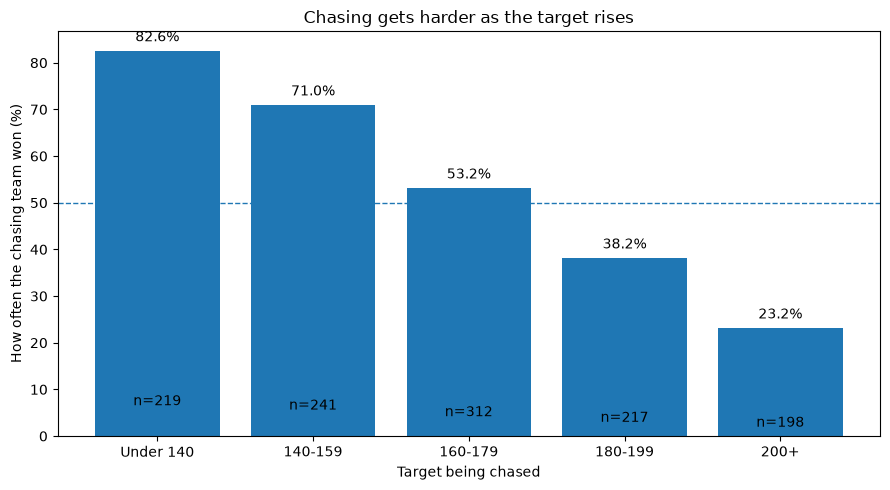

In [ ]:
df = h2_df.copy()

bands = df["target_band"]
rates = df["chase_win_rate_pct"]
counts = df["n_matches"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(bands, rates)

ax.set_title("Chasing gets harder as the target rises")
ax.set_xlabel("Target being chased")
ax.set_ylabel("How often the chasing team won (%)")

ax.axhline(50, linestyle="--", linewidth=1)

for bar, n, rate in zip(bars, counts, rates):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        max(2, rate * 0.08),
        f"n={int(n)}",
        ha="center"
    )

    ax.text(
        bar.get_x() + bar.get_width()/2,
        rate + 2,
        f"{rate:.1f}%",
        ha="center"
    )

fig.tight_layout()

fig.savefig(
    FIG_DIR / "chase_win_rate_target_band.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

C1 — Runs and wickets by phase

In [ ]:
c1_df = q("""
SELECT
    phase,
    ROUND(6.0 * SUM(total_runs) / SUM(is_legal), 2) AS runs_per_over,
    ROUND(
        100.0 * SUM(bowler_wicket) / SUM(is_legal),
        2
    ) AS wickets_per_100_balls
FROM v_ball
WHERE phase IN ('Powerplay', 'Middle', 'Death')
GROUP BY phase
ORDER BY
    CASE phase
        WHEN 'Powerplay' THEN 1
        WHEN 'Middle' THEN 2
        WHEN 'Death' THEN 3
    END;
""")

c1_df

,phase,runs_per_over,wickets_per_100_balls
0,Powerplay,8.03,3.78
1,Middle,7.92,4.07
2,Death,10.04,7.43


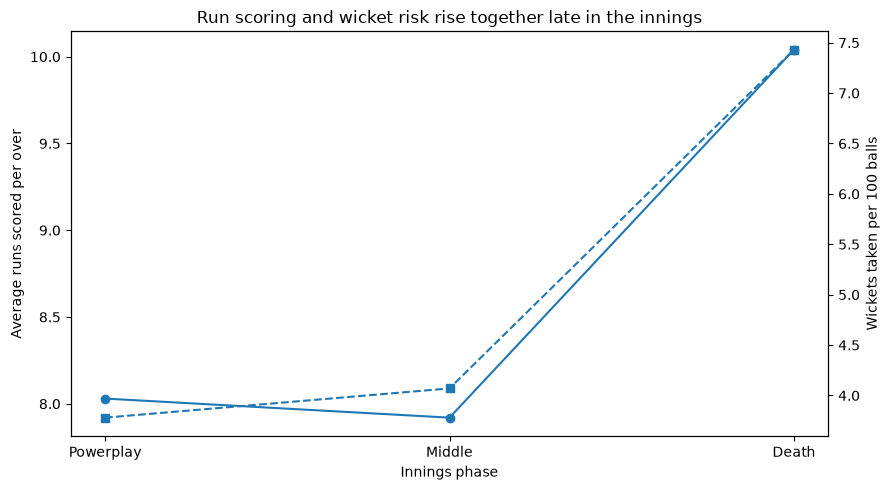

In [ ]:
df = c1_df.copy()

phase = df["phase"]
runs = df["runs_per_over"]
wicket_rate = df["wickets_per_100_balls"]

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(phase, runs, marker="o")

ax1.set_xlabel("Innings phase")
ax1.set_ylabel("Average runs scored per over")

ax2 = ax1.twinx()

ax2.plot(
    phase,
    wicket_rate,
    marker="s",
    linestyle="--"
)

ax2.set_ylabel("Wickets taken per 100 balls")

ax1.set_title(
    "Run scoring and wicket risk rise together late in the innings"
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "runs_wickets_by_phase.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

G3 — Toss split

In [ ]:
g3_df = q("""
SELECT
    toss_decision AS group_label,
    COUNT(*) AS n_matches,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN toss_winner = match_winner THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS win_rate_pct
FROM matches_clean
WHERE result = 'win'
GROUP BY toss_decision;
""")

g3_df

,group_label,n_matches,win_rate_pct
0,bat,402,45.77
1,field,785,54.65


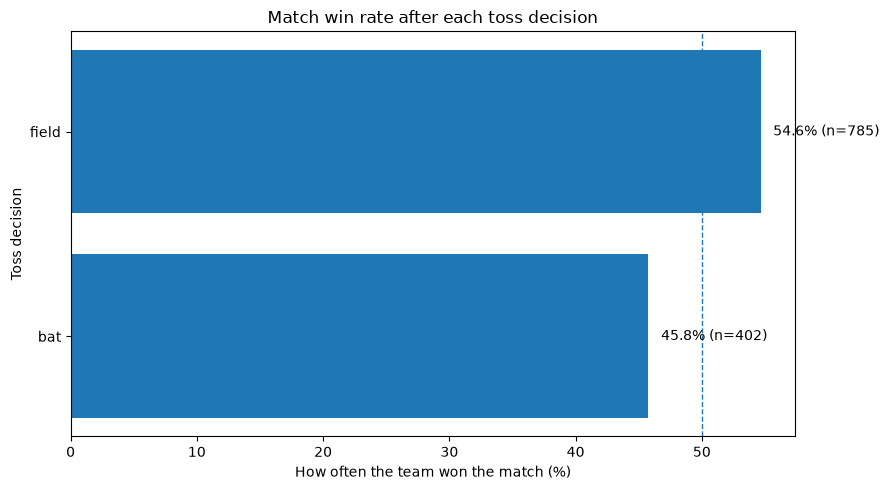

In [ ]:
df = g3_df.copy()

labels = df["group_label"]
rates = df["win_rate_pct"]
counts = df["n_matches"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(labels, rates)

ax.axvline(
    50,
    linestyle="--",
    linewidth=1
)

ax.set_title("Match win rate after each toss decision")
ax.set_xlabel("How often the team won the match (%)")
ax.set_ylabel("Toss decision")

for bar, rate, n in zip(bars, rates, counts):
    ax.text(
        rate + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}% (n={int(n)})",
        va="center"
    )

fig.tight_layout()

fig.savefig(
    FIG_DIR / "toss_split.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

I1 — Venue before/after cleaning

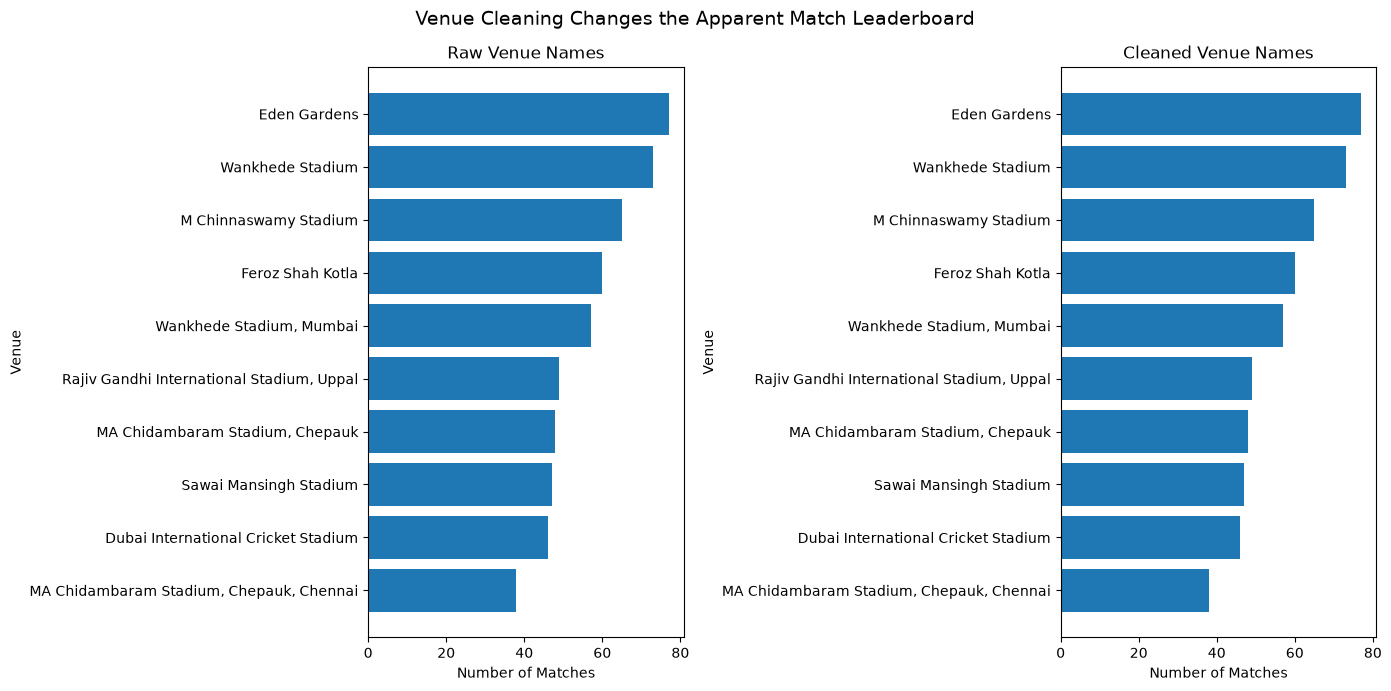

In [ ]:
# CHART 4: VENUE BEFORE AND AFTER CLEANING

# Raw venue data
raw = q("""
SELECT
    venue,
    COUNT(*) AS matches
FROM matches
WHERE venue IS NOT NULL
GROUP BY venue
ORDER BY matches DESC;
""")

# Cleaned venue data
# matches_clean uses the existing 'venue' column
clean = q("""
SELECT
    venue,
    COUNT(*) AS matches
FROM matches_clean
WHERE venue IS NOT NULL
GROUP BY venue
ORDER BY matches DESC;
""")

# Select top 10 venues
raw_top = raw.head(10).sort_values("matches")
clean_top = clean.head(10).sort_values("matches")

# Create chart
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7)
)

# Raw venue names
axes[0].barh(
    raw_top["venue"],
    raw_top["matches"]
)

axes[0].set_title("Raw Venue Names")
axes[0].set_xlabel("Number of Matches")
axes[0].set_ylabel("Venue")


# Cleaned venue names
axes[1].barh(
    clean_top["venue"],
    clean_top["matches"]
)

axes[1].set_title("Cleaned Venue Names")
axes[1].set_xlabel("Number of Matches")
axes[1].set_ylabel("Venue")


# Main heading
fig.suptitle(
    "Venue Cleaning Changes the Apparent Match Leaderboard",
    fontsize=14
)

fig.tight_layout()

# Save chart
fig.savefig(
    FIG_DIR / "venue_before_after.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

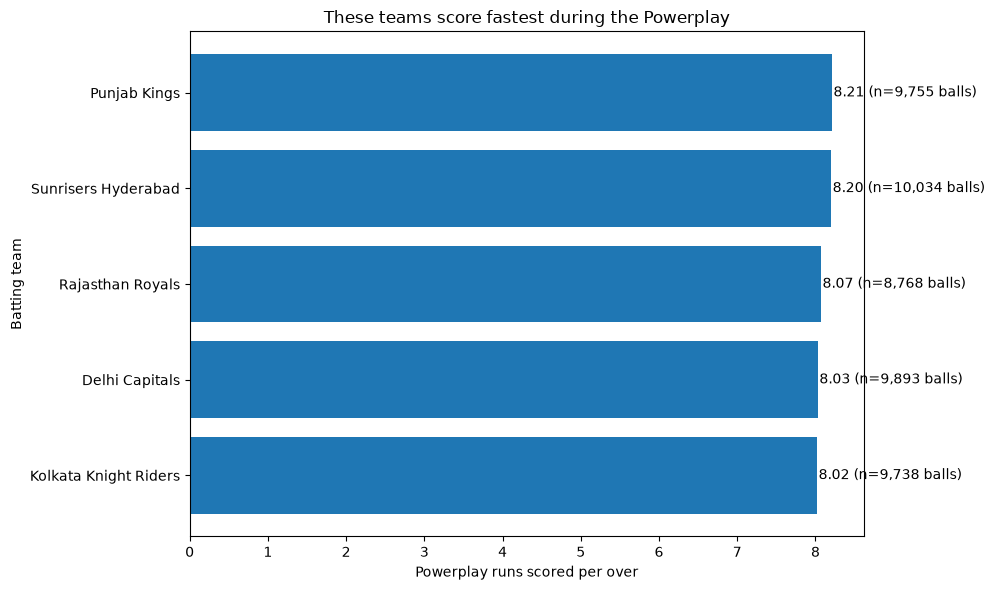

In [ ]:
# J3 - Which team scores fastest in the Powerplay?
j3_df = q("""
SELECT batting_team,
       SUM(is_legal) AS balls,
       ROUND(
           6.0*SUM(total_runs)/SUM(is_legal),
           2
       ) AS pp_run_rate
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batting_team
HAVING SUM(is_legal) >= 3000
ORDER BY pp_run_rate DESC
LIMIT 5;
""")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    j3_df["batting_team"][::-1],
    j3_df["pp_run_rate"][::-1]
)
ax.set_title(
    "These teams score fastest during the Powerplay"
)
ax.set_xlabel(
    "Powerplay runs scored per over"
)
ax.set_ylabel(
    "Batting team"
)
for bar, rate, n in zip(
    bars,
    j3_df["pp_run_rate"][::-1],
    j3_df["balls"][::-1]
):
    ax.text(
        rate + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"{rate:.2f} (n={int(n):,} balls)",
        va="center"
    )
fig.tight_layout()
fig.savefig(
    FIG_DIR / "powerplay_team_run_rate.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

6. Check that all 5 charts were saved

In [ ]:
# Check saved charts
for file in FIG_DIR.glob("*.png"):
    print(file.name)

chase_win_rate_target_band.png
powerplay_team_run_rate.png
runs_wickets_by_phase.png
specialism_season_scoring.png
toss_split.png
venue_before_after.png


# Ipl ipynb Charts

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect(r"..\data\raw\ipl.db")                       
pd.read_csv(r"..\data\raw\Tables\matches.csv").to_sql("matches", con, if_exists="replace", index=False)  # add match table

print("tables:", pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name.tolist())

tables: ['deliveries', 'teams', 'players', 'venues', 'matches_clean', 'matches']


1. Chase win rate by first-innings target (H2) — bar

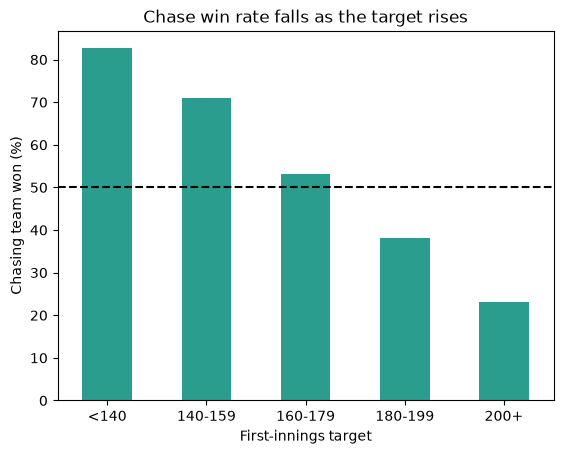

In [ ]:
df = pd.read_sql("""
    WITH first_inn AS (SELECT match_id, SUM(total_runs) target
                       FROM deliveries WHERE is_super_over=0 AND innings=1 GROUP BY match_id),
         chaser AS (SELECT match_id, MIN(batting_team) team2
                    FROM deliveries WHERE is_super_over=0 AND innings=2 GROUP BY match_id)
    SELECT CASE WHEN target<140 THEN '<140' WHEN target<160 THEN '140-159'
                WHEN target<180 THEN '160-179' WHEN target<200 THEN '180-199'
                ELSE '200+' END AS target_band,
           ROUND(100.0*AVG(CASE WHEN c.team2=m.match_winner THEN 1 ELSE 0 END),1) AS win_pct
    FROM first_inn f JOIN chaser c USING(match_id) JOIN matches m USING(match_id)
    WHERE m.result='win'
    GROUP BY target_band ORDER BY MIN(target)
""", con, index_col="target_band")
df.plot(kind="bar", rot=0, legend=False, color="#2a9d8f",
        title="Chase win rate falls as the target rises",
        xlabel="First-innings target", ylabel="Chasing team won (%)")
plt.axhline(50, ls="--", c="k"); plt.show()

2. Runs per over by phase (C1) — bar

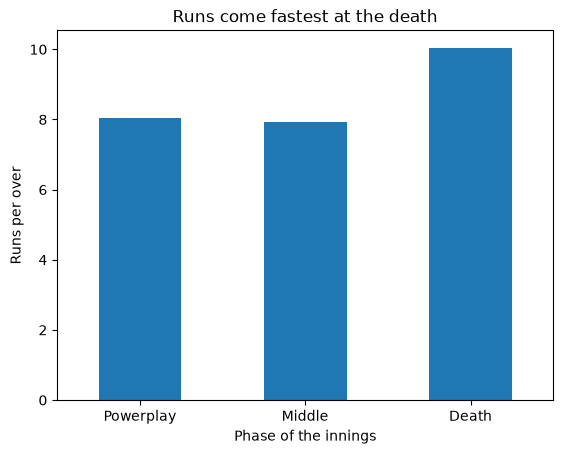

In [ ]:
df = pd.read_sql("""
    SELECT CASE WHEN over_number<=5 THEN 'Powerplay'
                WHEN over_number<=14 THEN 'Middle' ELSE 'Death' END AS phase,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS runs_per_over
    FROM deliveries WHERE is_super_over=0
    GROUP BY phase ORDER BY MIN(over_number)
""", con, index_col="phase")
df.plot(kind="bar", rot=0, legend=False, color="#1f77b4",
        title="Runs come fastest at the death",
        xlabel="Phase of the innings", ylabel="Runs per over")
plt.show()

3. How captains use the toss (G3) — pie


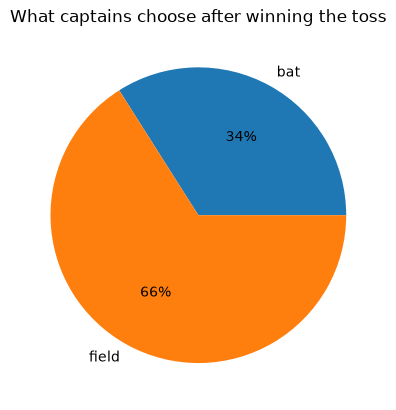

In [ ]:
df = pd.read_sql("""
    SELECT toss_decision, COUNT(*) AS matches
    FROM matches GROUP BY toss_decision
""", con, index_col="toss_decision")
df.plot(kind="pie", y="matches", autopct="%.0f%%", legend=False, ylabel="",
        title="What captains choose after winning the toss")
plt.show()

4. Pace against spin (E) — bar

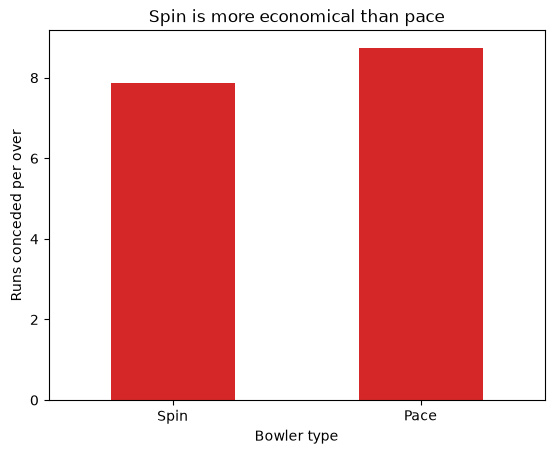

In [ ]:
df = pd.read_sql("""
    SELECT CASE WHEN LOWER(bowler_type) LIKE '%break%' OR LOWER(bowler_type) LIKE '%orthodox%'
                  OR LOWER(bowler_type) LIKE '%wrist spin%' OR LOWER(bowler_type) LIKE '%googly%'
                THEN 'Spin' ELSE 'Pace' END AS bowler_kind,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS economy
    FROM deliveries WHERE is_super_over=0 AND TRIM(bowler_type)<>''
    GROUP BY bowler_kind ORDER BY bowler_kind DESC
""", con, index_col="bowler_kind")
df.plot(kind="bar", rot=0, legend=False, color=["#d62728","#1f77b4"],
        title="Spin is more economical than pace",
        xlabel="Bowler type", ylabel="Runs conceded per over")
plt.show()

5. First-innings scores by season (L) — line

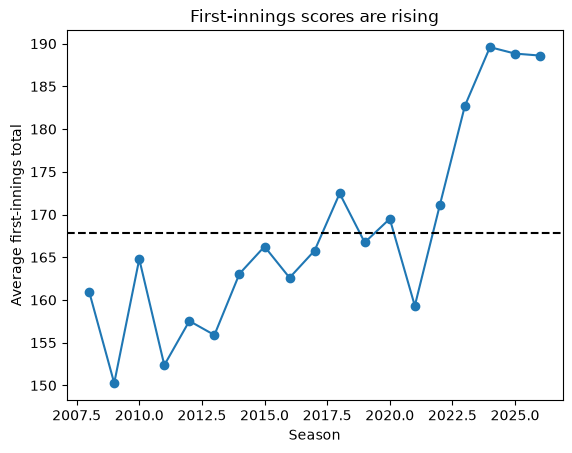

In [ ]:
df = pd.read_sql("""
    SELECT season_id, AVG(total) AS avg_first_innings FROM (
        SELECT season_id, match_id, SUM(total_runs) AS total
        FROM deliveries WHERE is_super_over=0 AND innings=1
        GROUP BY season_id, match_id)
    GROUP BY season_id ORDER BY season_id
""", con, index_col="season_id")
df.plot(kind="line", marker="o", legend=False, color="#1f77b4",
        title="First-innings scores are rising",
        xlabel="Season", ylabel="Average first-innings total")
plt.axhline(df.avg_first_innings.mean(), ls="--", c="k"); plt.show()

6. Left-hand against right-hand batters (A8) — bar

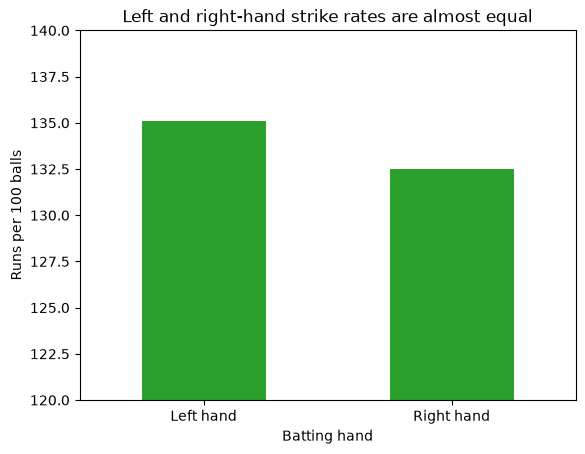

In [ ]:
df = pd.read_sql("""
    SELECT CASE WHEN LOWER(batsman_type) LIKE '%left%' THEN 'Left hand' ELSE 'Right hand' END AS batting_hand,
           SUM(batter_runs)*100.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS strike_rate
    FROM deliveries WHERE is_super_over=0 AND TRIM(batsman_type)<>''
    GROUP BY batting_hand
""", con, index_col="batting_hand")
df.plot(kind="bar", rot=0, legend=False, ylim=(120,140), color=["#2ca02c","#1f77b4"],
        title="Left and right-hand strike rates are almost equal",
        xlabel="Batting hand", ylabel="Runs per 100 balls")
plt.show()

7. How wickets fall (K) — horizontal bar

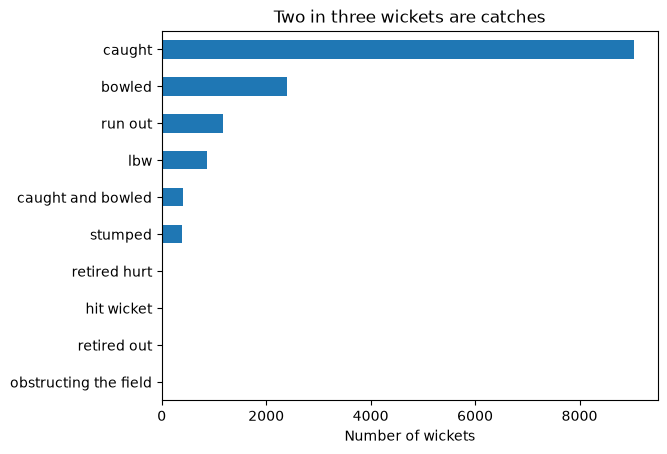

In [ ]:
df = pd.read_sql("""
    SELECT wicket_kind, COUNT(*) AS wickets
    FROM deliveries WHERE is_super_over=0 AND is_wicket=1 AND TRIM(COALESCE(wicket_kind,''))<>''
    GROUP BY wicket_kind ORDER BY wickets
""", con, index_col="wicket_kind")
df.plot(kind="barh", legend=False, color="#1f77b4",
        title="Two in three wickets are catches",
        xlabel="Number of wickets", ylabel="")
plt.show()

8. Top 10 run scorers — horizontal bar

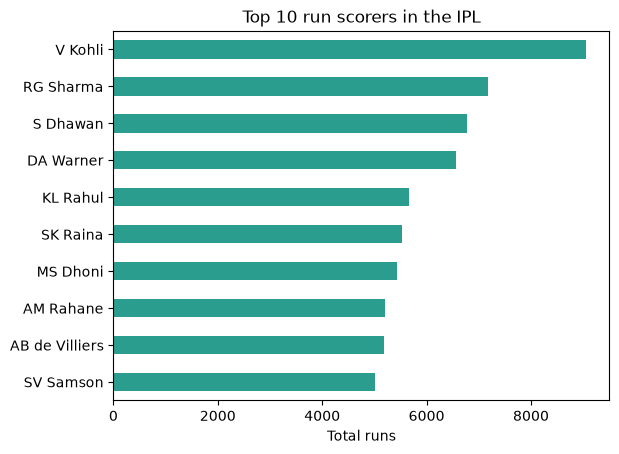

In [ ]:
df = pd.read_sql("""
    SELECT * FROM (
        SELECT batter, SUM(batter_runs) AS runs
        FROM deliveries GROUP BY batter ORDER BY runs DESC LIMIT 10)
    ORDER BY runs
""", con, index_col="batter")
df.plot(kind="barh", legend=False, color="#2a9d8f",
        title="Top 10 run scorers in the IPL",
        xlabel="Total runs", ylabel="")
plt.show()

9. Top 10 wicket takers — horizontal bar

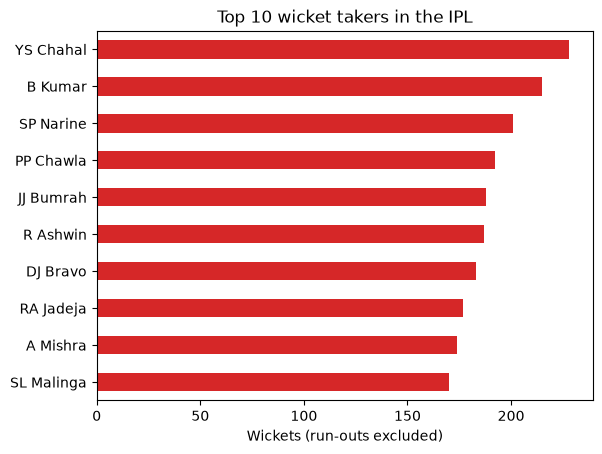

In [ ]:
df = pd.read_sql("""
    SELECT * FROM (
        SELECT bowler, COUNT(*) AS wickets
        FROM deliveries
        WHERE is_wicket=1 AND wicket_kind NOT IN ('run out','retired hurt','retired out','obstructing the field')
        GROUP BY bowler ORDER BY wickets DESC LIMIT 10)
    ORDER BY wickets
""", con, index_col="bowler")
df.plot(kind="barh", legend=False, color="#d62728",
        title="Top 10 wicket takers in the IPL",
        xlabel="Wickets (run-outs excluded)", ylabel="")
plt.show()

10. Scoring over by over (1-20) — line

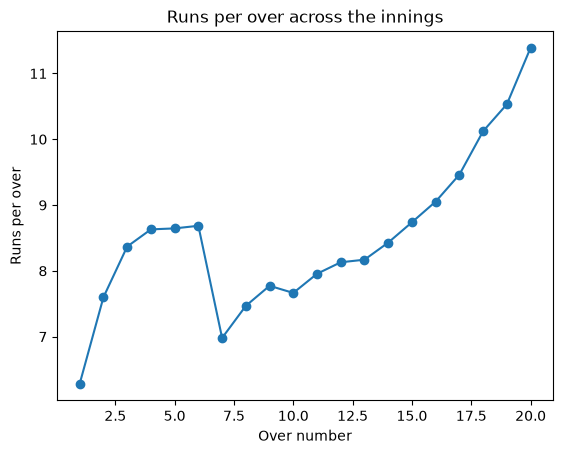

In [ ]:
df = pd.read_sql("""
    SELECT over_number+1 AS over_no,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS runs_per_over
    FROM deliveries WHERE is_super_over=0
    GROUP BY over_number ORDER BY over_number
""", con, index_col="over_no")
df.plot(kind="line", marker="o", legend=False, color="#1f77b4",
        title="Runs per over across the innings",
        xlabel="Over number", ylabel="Runs per over")
plt.show()

11. Where the runs come from — pie

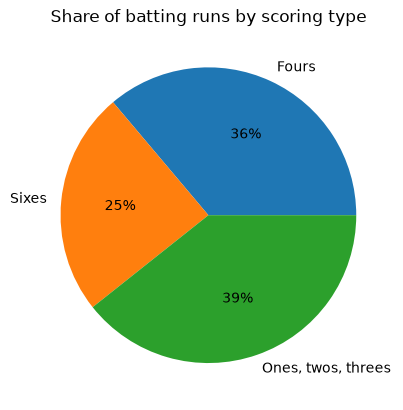

In [ ]:
df = pd.read_sql("""
    SELECT 'Fours' AS run_type, SUM(CASE WHEN batter_runs=4 THEN 4 ELSE 0 END) AS runs FROM deliveries WHERE is_super_over=0
    UNION ALL SELECT 'Sixes', SUM(CASE WHEN batter_runs=6 THEN 6 ELSE 0 END) FROM deliveries WHERE is_super_over=0
    UNION ALL SELECT 'Ones, twos, threes', SUM(CASE WHEN batter_runs NOT IN (4,6) THEN batter_runs ELSE 0 END) FROM deliveries WHERE is_super_over=0
""", con, index_col="run_type")
df.plot(kind="pie", y="runs", autopct="%.0f%%", legend=False, ylabel="",
        title="Share of batting runs by scoring type")
plt.show()

12. Venue names before and after cleaning (I1) — bar

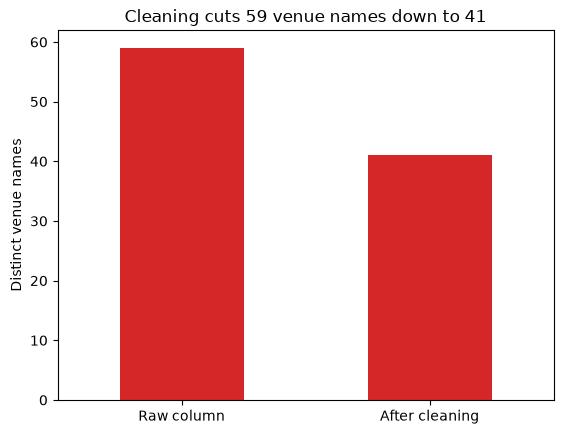

In [ ]:
df = pd.read_sql("""
    SELECT 'Raw column' AS stage, COUNT(DISTINCT venue) AS venue_count FROM matches
    UNION ALL
    SELECT 'After cleaning',
           COUNT(DISTINCT CASE WHEN INSTR(venue, ',') > 0                         -- name has a city after a comma
                               THEN TRIM(REPLACE(SUBSTR(venue, 1, INSTR(venue, ',') - 1), '.', ' '))
                               ELSE TRIM(REPLACE(venue, '.', ' ')) END)           -- name has no comma
    FROM matches
""", con, index_col="stage")
df.plot(kind="bar", rot=0, legend=False, color=["#d62728","#2ca02c"],
        title="Cleaning cuts 59 venue names down to 41",
        xlabel="", ylabel="Distinct venue names")
plt.show()